# Практическая работа № 10
## Методы расстояний для выявления аномалий в кибербезопасности

Решение выполнено на приложенном `cyber_distance_anomalies.csv` по заданиям и материалам лекции. Запускайте ячейки сверху вниз. Код снабжён подробными комментариями, а интерпретация результатов находится в текстовых ячейках.

`scenario` и `is_attack` — учебные метки для проверки качества после получения предсказаний. Они не участвуют в масштабировании, поиске соседей, обучении LOF и выборе порогов. `traffic_type` используется только для сохранения долей нормальных типов трафика при разделении выборки.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Показываем все столбцы и достаточную ширину таблиц с результатами.
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

In [9]:
# Во всех моделях используются только три числовых признака сессии.
FEATURES = ['connections_per_min', 'unique_destinations', 'outbound_mb']

# CSV лежит рядом с блокнотом, поэтому читаем его по имени файла.
df = pd.read_csv('cyber_distance_anomalies.csv')

# Исторические подтверждённо нормальные события и новые события мониторинга.
reference_df = df.loc[df['dataset_part'] == 'reference_normal'].copy()
monitoring_df = df.loc[df['dataset_part'] == 'monitoring'].copy()
monitoring_df = monitoring_df.reset_index(drop=True)

print('Вся выборка:', df.shape)
print('Профиль нормы:', reference_df.shape)
print('Мониторинг:', monitoring_df.shape)

Вся выборка: (854, 8)
Профиль нормы: (600, 8)
Мониторинг: (254, 8)


### Вспомогательные функции

Одна функция считает качество по учебной разметке, другая показывает обнаружение по сценариям. Метки используются только здесь, после расчёта оценок и предсказаний.

In [10]:
def quality_row(method, mode, threshold, prediction):
    # Матрица ошибок при labels=[0, 1] имеет вид [[TN, FP], [FN, TP]].
    # Значения получаем на одних и тех же 254 событиях мониторинга.
    tn, fp, fn, tp = confusion_matrix(
        monitoring_df['is_attack'], prediction, labels=[0, 1]
    ).ravel()
    return {'Метод': method, 'Режим': mode, 'Порог': threshold,
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}


def detected_by_scenario(prediction):
    # Выбираем только размеченные атаки и считаем находки каждого сценария.
    attack_mask = monitoring_df['is_attack'].to_numpy() == 1
    attacks = monitoring_df.loc[attack_mask, ['scenario']].copy()
    attacks['Обнаружено'] = np.asarray(prediction)[attack_mask]
    return attacks.groupby('scenario')['Обнаружено'].agg(['sum', 'count'])

## Задание 1. Подготовка данных и режимов работы — 3 балла
Проведите аудит набора, подготовьте стандартизованную смешанную выборку и раздельные выборки `normal_fit`, `normal_calibration`, `monitoring`. Объясните, почему служебные метки не входят в признаки и почему scaler профиля нормы обучается только на `normal_fit`.

In [11]:
# Аудит требуется по заданию: смотрим структуру и качество данных.
print('Типы столбцов:')
display(df.dtypes.to_frame('Тип'))
print('Число пропусков по столбцам:')
display(df.isna().sum().to_frame('Пропусков'))
print('Полных дубликатов:', int(df.duplicated().sum()))
print('Сценарии в частях набора:')
display(pd.crosstab(df['dataset_part'], df['scenario']))

# В смешанном режиме среднее и стандартное отклонение признаков
# вычисляем по мониторинговым событиям без использования меток.
mixed_scaler = StandardScaler()
X_unsupervised = mixed_scaler.fit_transform(monitoring_df[FEATURES])

# 75% подтверждённой нормы идёт на обучение, 25% — на порог.
# stratify сохраняет доли типов web, api и backup в обеих частях.
normal_fit_df, normal_calibration_df = train_test_split(
    reference_df, test_size=0.25, random_state=42,
    stratify=reference_df['traffic_type']
)
normal_fit_df = normal_fit_df.reset_index(drop=True)
normal_calibration_df = normal_calibration_df.reset_index(drop=True)

# В режиме профиля нормы scaler обучается только на normal_fit_df.
# Отложенная калибровка и мониторинг не меняют его параметры.
normal_scaler = StandardScaler()
X_normal_fit = normal_scaler.fit_transform(normal_fit_df[FEATURES])
X_normal_calibration = normal_scaler.transform(
    normal_calibration_df[FEATURES]
)
X_monitoring = normal_scaler.transform(monitoring_df[FEATURES])

print('Размеры: fit', len(normal_fit_df),
      '| calibration', len(normal_calibration_df),
      '| monitoring', len(monitoring_df))
print('Типы трафика после разделения нормы:')
display(pd.DataFrame({
    'fit': normal_fit_df['traffic_type'].value_counts(),
    'calibration': normal_calibration_df['traffic_type'].value_counts()
}).fillna(0).astype(int))

Типы столбцов:


,Тип
session_id,object
connections_per_min,float64
unique_destinations,float64
outbound_mb,float64
traffic_type,object
scenario,object
is_attack,int64
dataset_part,object


Число пропусков по столбцам:


,Пропусков
session_id,0
connections_per_min,0
unique_destinations,0
outbound_mb,0
traffic_type,0
scenario,0
is_attack,0
dataset_part,0


Полных дубликатов: 0
Сценарии в частях набора:


scenario,beaconing,exfiltration,lateral_movement,normal,port_scan
dataset_part,,,,,
monitoring,4,3,3,240,4
reference_normal,0,0,0,600,0


Размеры: fit 450 | calibration 150 | monitoring 254
Типы трафика после разделения нормы:


,fit,calibration
traffic_type,,
web,270,90
api,135,45
backup,45,15


### Вывод по заданию 1

В наборе 854 сессии и 8 исходных столбцов; пропусков и полных дубликатов нет. Историческая часть содержит 600 подтверждённо нормальных событий, мониторинг — 240 нормальных и 14 атакующих по учебной разметке. Нормальная часть разделена на 450 событий для обучения и 150 для калибровки; доли web, api и backup сохранены. В смешанном режиме масштабирование рассчитывается по мониторингу, а в режиме профиля нормы — только по `normal_fit_df`. Это не даёт калибровочным и новым событиям изменить масштаб эталонного профиля до оценки их аномальности. `scenario` и `is_attack` используются только после получения прогнозов, чтобы измерить качество методов.

## Задание 2. kNN в двух режимах — 6 баллов
Используйте `k=10`, евклидово расстояние и среднее расстояние до соседей. В смешанном режиме исключите сам объект вызовом `kneighbors()` без `X` и выберите порог по доле 0,055. Для профиля нормы выберите 99-й процентиль оценок калибровочной нормы. Выведите пороги, TP, FP, FN, TN и обнаружение по сценариям.

In [12]:
# Один список собирает качество всех четырёх сочетаний метода и режима.
results = []
K = 10

# Смешанный режим: ищем соседей среди всех сессий мониторинга.
knn_mixed = NearestNeighbors(n_neighbors=K, metric='euclidean')
knn_mixed.fit(X_unsupervised)

# kneighbors() БЕЗ X исключает сам объект из его списка соседей.
# Для каждой строки получаем десять расстояний и берём их среднее.
mixed_distances, mixed_indices = knn_mixed.kneighbors()
knn_mixed_scores = mixed_distances.mean(axis=1)

# Порог 94,5-го процентиля соответствует предполагаемой доле 5,5%.
# Эта доля задана в задании; она не вычисляется по is_attack.
knn_mixed_threshold = np.quantile(knn_mixed_scores, 1 - 0.055)
knn_mixed_prediction = (knn_mixed_scores > knn_mixed_threshold).astype(int)
results.append(quality_row('kNN', 'Смешанный',
                           knn_mixed_threshold, knn_mixed_prediction))

# Профиль нормы: эталонными соседями служат только normal_fit_df.
knn_normal = NearestNeighbors(n_neighbors=K, metric='euclidean')
knn_normal.fit(X_normal_fit)

# Калибровка и мониторинг не входили в обучение, поэтому передаём их
# в kneighbors(X). Их самих в normal_fit нет, исключать их не требуется.
calibration_distances, _ = knn_normal.kneighbors(X_normal_calibration)
knn_calibration_scores = calibration_distances.mean(axis=1)
knn_normal_threshold = np.quantile(knn_calibration_scores, 0.99)

monitoring_distances, monitoring_indices = knn_normal.kneighbors(X_monitoring)
knn_normal_scores = monitoring_distances.mean(axis=1)
knn_normal_prediction = (knn_normal_scores > knn_normal_threshold).astype(int)
results.append(quality_row('kNN', 'Профиль нормы',
                           knn_normal_threshold, knn_normal_prediction))

display(pd.DataFrame(results).round({'Порог': 4}))
print('Обнаружение атак по сценариям, смешанный режим:')
display(detected_by_scenario(knn_mixed_prediction))
print('Обнаружение атак по сценариям, профиль нормы:')
display(detected_by_scenario(knn_normal_prediction))

,Метод,Режим,Порог,TP,FP,FN,TN
0,kNN,Смешанный,0.4214,14,0,0,240
1,kNN,Профиль нормы,0.4573,14,1,0,239


Обнаружение атак по сценариям, смешанный режим:


,sum,count
scenario,,
beaconing,4,4
exfiltration,3,3
lateral_movement,3,3
port_scan,4,4


Обнаружение атак по сценариям, профиль нормы:


,sum,count
scenario,,
beaconing,4,4
exfiltration,3,3
lateral_movement,3,3
port_scan,4,4


### Вывод по заданию 2

Смешанный kNN при пороге 0,4214 обнаружил все 14 атак, не дал ложных тревог и правильно отнёс к норме все 240 нормальных событий мониторинга. Профиль нормы при калибровочном пороге 0,4573 также нашёл все атаки, но отметил одно нормальное событие как тревогу. В обоих режимах обнаружены все четыре `port_scan`, четыре `beaconing`, три `exfiltration` и три `lateral_movement`. Оценка kNN — среднее евклидово расстояние до десяти соседей после стандартизации признаков; большее расстояние означает более необычную сессию. При поиске соседей внутри смешанной обучающей выборки саму проверяемую сессию исключаем, иначе нулевое расстояние искусственно уменьшило бы её оценку.

## Задание 3. LOF в двух режимах — 6 баллов
Используйте `n_neighbors=20`. В смешанном режиме задайте `contamination=0.055`, `novelty=False`, примените `fit_predict()` и смените знак `negative_outlier_factor_`. Для профиля нормы задайте `novelty=True`, получите положительные оценки через `-score_samples()` и выберите 99-й процентиль калибровочной нормы.

In [13]:
# Смешанный LOF сравнивает плотность каждой точки с плотностью
# её соседей в мониторинговой выборке.
lof_mixed = LocalOutlierFactor(
    n_neighbors=20, metric='euclidean',
    contamination=0.055, novelty=False
)

# fit_predict возвращает 1 для нормы и -1 для аномалии.
# negative_outlier_factor_ имеет обратный знак; после смены знака
# большие значения означают более сильную аномальность.
lof_mixed_labels = lof_mixed.fit_predict(X_unsupervised)
lof_mixed_scores = -lof_mixed.negative_outlier_factor_
lof_mixed_threshold = -lof_mixed.offset_
lof_mixed_prediction = (lof_mixed_labels == -1).astype(int)
results.append(quality_row('LOF', 'Смешанный',
                           lof_mixed_threshold, lof_mixed_prediction))

# novelty=True разрешает оценивать новые точки относительно обученной нормы.
lof_normal = LocalOutlierFactor(
    n_neighbors=20, metric='euclidean',
    contamination='auto', novelty=True
)
lof_normal.fit(X_normal_fit)

# score_samples возвращает отрицательную LOF-оценку.
# Меняем знак и выбираем 99-й процентиль отложенной нормы.
lof_calibration_scores = -lof_normal.score_samples(X_normal_calibration)
lof_normal_threshold = np.quantile(lof_calibration_scores, 0.99)
lof_normal_scores = -lof_normal.score_samples(X_monitoring)

# Используем собственный калибровочный порог, поэтому не вызываем predict().
lof_normal_prediction = (lof_normal_scores > lof_normal_threshold).astype(int)
results.append(quality_row('LOF', 'Профиль нормы',
                           lof_normal_threshold, lof_normal_prediction))

display(pd.DataFrame(results[-2:]).round({'Порог': 4}))
print('Обнаружение атак по сценариям, смешанный режим:')
display(detected_by_scenario(lof_mixed_prediction))
print('Обнаружение атак по сценариям, профиль нормы:')
display(detected_by_scenario(lof_normal_prediction))

,Метод,Режим,Порог,TP,FP,FN,TN
0,LOF,Смешанный,2.3693,14,0,0,240
1,LOF,Профиль нормы,1.8006,14,1,0,239


Обнаружение атак по сценариям, смешанный режим:


,sum,count
scenario,,
beaconing,4,4
exfiltration,3,3
lateral_movement,3,3
port_scan,4,4


Обнаружение атак по сценариям, профиль нормы:


,sum,count
scenario,,
beaconing,4,4
exfiltration,3,3
lateral_movement,3,3
port_scan,4,4


### Вывод по заданию 3

Смешанный LOF при положительном пороге 2,3693 обнаружил все 14 атак без ложных тревог; профиль нормы при калибровочном пороге 1,8006 нашёл все атаки и дал одну ложную тревогу. По каждому из четырёх атакующих сценариев обнаружены все размеченные сессии. LOF сравнивает локальную плотность сессии с плотностью её соседей: после смены знака большие оценки соответствуют большей аномальности. В смешанном режиме `fit_predict()` даёт метки для обучающей выборки, а в режиме `novelty=True` новые сессии оцениваются через `score_samples()` и сравниваются с порогом, рассчитанным по отдельной нормальной калибровке. Поэтому встроенный порог `predict()` не подменяет заданный калибровочный порог.

## Задание 4. Сравнение и интерпретация для SOC — 5 баллов
Сведите результаты четырёх комбинаций метода и режима в таблицу, постройте гистограммы оценок с порогами и исследуйте нормальных соседей наиболее аномальной по kNN сессии. Подготовьте аналитическую записку SOC из 5–7 предложений.

,Метод,Режим,Порог,TP,FP,FN,TN
0,kNN,Смешанный,0.4214,14,0,0,240
1,kNN,Профиль нормы,0.4573,14,1,0,239
2,LOF,Смешанный,2.3693,14,0,0,240
3,LOF,Профиль нормы,1.8006,14,1,0,239


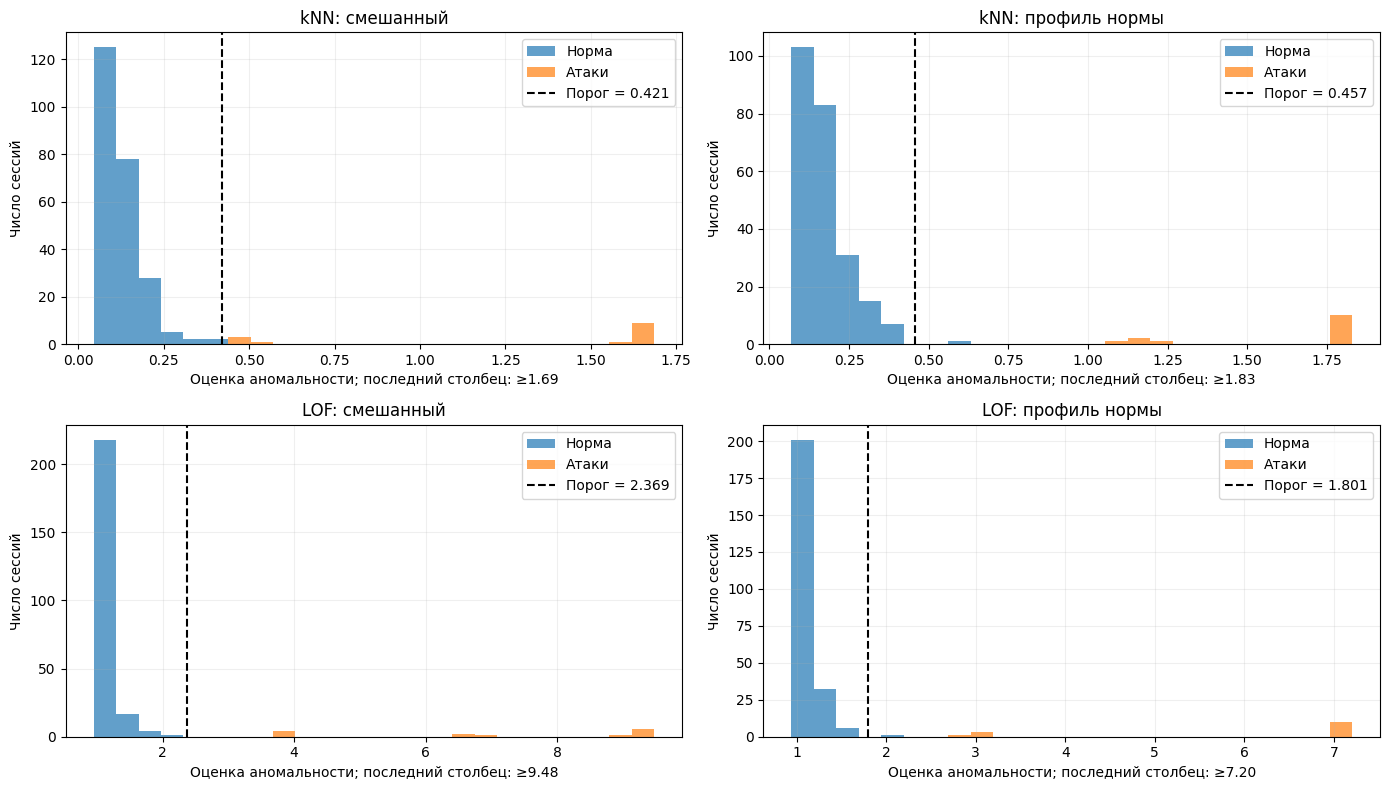

Самая необычная по kNN сессия относительно профиля нормы:


,session_id,connections_per_min,unique_destinations,outbound_mb,scenario
241,S0841,205.6,168.93,5.68,port_scan


Её среднее расстояние до 10 нормальных соседей: 28.9771
10 ближайших нормальных сессий:


,session_id,connections_per_min,unique_destinations,outbound_mb,distance
0,S0081,71.71,21.31,21.44,28.7315
1,S0315,57.01,21.40,25.06,28.7553
2,S0097,57.04,20.57,16.87,28.9134
3,S0286,70.75,20.32,31.08,28.9262
4,S0240,57.95,20.12,19.81,28.9975
5,S0136,64.74,19.93,41.23,29.0201
6,S0068,69.42,19.64,35.23,29.0615
7,S0078,57.09,19.56,31.85,29.1098
8,S0080,60.15,19.43,29.75,29.1256
9,S0299,61.96,19.38,26.80,29.1296


Средние значения признаков у соседей:


,Среднее соседей
connections_per_min,62.78
unique_destinations,20.17
outbound_mb,27.91


In [14]:
# Сводим четыре результата в одну таблицу для сравнения.
comparison = pd.DataFrame(results)
display(comparison.round({'Порог': 4}))

# Гистограммы показывают распределение оценок отдельно для нормы и атак.
# Метка нужна только для цвета столбцов; модели её не использовали.
normal_mask = monitoring_df['is_attack'].to_numpy() == 0
attack_mask = ~normal_mask
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
plots = [
    (axes[0, 0], knn_mixed_scores, knn_mixed_threshold, 'kNN: смешанный'),
    (axes[0, 1], knn_normal_scores, knn_normal_threshold, 'kNN: профиль нормы'),
    (axes[1, 0], lof_mixed_scores, lof_mixed_threshold, 'LOF: смешанный'),
    (axes[1, 1], lof_normal_scores, lof_normal_threshold, 'LOF: профиль нормы')
]

for ax, scores, threshold, title in plots:
    # Очень большие оценки сжимают основную часть гистограммы.
    # Только для рисунка объединяем их в последний столбец; пороги
    # и метрики выше рассчитаны по исходным, неограниченным оценкам.
    plot_limit = threshold * 4
    shown_scores = np.minimum(scores, plot_limit)
    bins = np.linspace(shown_scores.min(), plot_limit, 26)
    ax.hist(shown_scores[normal_mask], bins=bins, alpha=0.7, label='Норма')
    ax.hist(shown_scores[attack_mask], bins=bins, alpha=0.7, label='Атаки')
    ax.axvline(threshold, color='black', linestyle='--',
               label=f'Порог = {threshold:.3f}')
    ax.set_title(title)
    ax.set_xlabel(f'Оценка аномальности; последний столбец: ≥{plot_limit:.2f}')
    ax.set_ylabel('Число сессий')
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Наиболее аномальную по kNN сессию выбираем в режиме профиля нормы.
# Здесь все её соседи точно принадлежат подтверждённой норме.
most_unusual_position = int(np.argmax(knn_normal_scores))
most_unusual_session = monitoring_df.iloc[[most_unusual_position]][
    ['session_id', *FEATURES, 'scenario']
]
print('Самая необычная по kNN сессия относительно профиля нормы:')
display(most_unusual_session)
print('Её среднее расстояние до 10 нормальных соседей:',
      round(knn_normal_scores[most_unusual_position], 4))

# kneighbors возвращает ПОЗИЦИИ в normal_fit_df; выбираем их через iloc.
neighbor_positions = monitoring_indices[most_unusual_position]
neighbors = normal_fit_df.iloc[neighbor_positions][
    ['session_id', *FEATURES]
].copy()
neighbors['distance'] = monitoring_distances[most_unusual_position]
print('10 ближайших нормальных сессий:')
display(neighbors.reset_index(drop=True).round(4))
print('Средние значения признаков у соседей:')
display(neighbors[FEATURES].mean().round(2).to_frame('Среднее соседей'))

### Аналитическая записка SOC

Проанализированы 854 сетевые сессии: 600 подтверждённо нормальных использованы для построения профиля, а среди 254 сессий мониторинга учебная разметка указывает 14 атак. Для поиска необычных событий применены kNN с 10 соседями и LOF с 20 соседями в смешанном режиме и в режиме профиля нормы; пороги составили соответственно 0,4214 и 0,4573 для kNN, 2,3693 и 1,8006 для LOF. Все четыре варианта обнаружили 14 атак без пропусков: смешанные модели не дали ложных тревог, а модели профиля нормы дали по одной. Приоритетна сессия S0841 (`port_scan`): её среднее стандартизованное расстояние до десяти ближайших нормальных соседей равно 28,9771, а показатели соединений в минуту (205,60) и уникальных назначений (168,93) намного выше средних у соседей — 62,78 и 20,17. Следует проверить источники и адреса назначения S0841, связанные события сканирования S0840–S0843, а также журналы передачи данных и действий пользователей для остальных отмеченных сессий. Результаты относятся к этому учебному набору: пороги зависят от масштаба признаков, состава нормального трафика и выбранного числа соседей, поэтому перед применением в SOC их нужно проверить на новых данных.